# Chapter 11: Novelty and Outlier Detection

This notebook covers Chapter 11 of *scikit-learn Cookbook* (3rd Edition, Packt). **Anomalies** are observations that differ strongly from the majority of the data. Detecting them is important for fraud detection, network intrusion detection, equipment monitoring, and data cleaning.

**Topics covered:**
- Outlier detection vs. novelty detection
- Simple statistical methods: z-score and IQR
- Elliptic Envelope (robust covariance)
- Isolation Forest
- Local Outlier Factor (LOF), in outlier and novelty mode
- One-Class SVM
- The `contamination` parameter and anomaly scores
- Evaluating detectors when labels are available
- Comparing methods on data of different shapes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score


def plot_detector(ax, model, X, title, novelty_mode=True):
    """Draw the decision regions of a fitted detector and the data points."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    if novelty_mode:
        Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, Z, levels=20, cmap='Blues_r', alpha=0.5)
        ax.contour(xx, yy, Z, levels=[0], colors='red', linewidths=2)
    ax.set_title(title)

## 1. Outliers vs. Novelties

scikit-learn distinguishes two related tasks:
- **Outlier detection** (unsupervised): the training data itself **contains** anomalies, and the goal is to find them. The model must tolerate the contamination while learning what "normal" looks like.
- **Novelty detection** (semi-supervised): the training data is assumed to be **clean** (only normal points), and the goal is to decide whether **new** observations are anomalous.

All detectors share a common API:
- `fit(X)` learns the normal pattern.
- `predict(X)` returns **+1 for inliers** and **-1 for outliers**.
- `decision_function(X)` / `score_samples(X)` return a continuous score, where lower means more abnormal.
- `contamination` sets the expected share of outliers, which determines the decision threshold.

The example data has 300 normal points in two groups plus 20 scattered anomalies.

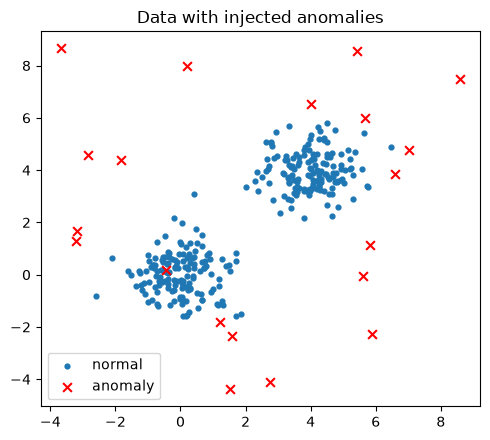

Share of anomalies (contamination): 0.062


In [2]:
rng = np.random.default_rng(42)
X_normal, _ = make_blobs(n_samples=300, centers=[[0, 0], [4, 4]], cluster_std=0.8,
                         random_state=42)
X_anom = rng.uniform(low=-5, high=9, size=(20, 2))

X = np.vstack([X_normal, X_anom])
y_true = np.r_[np.ones(len(X_normal)), -np.ones(len(X_anom))].astype(int)   # 1 = normal, -1 = anomaly
contamination = len(X_anom) / len(X)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(*X_normal.T, s=12, label='normal')
ax.scatter(*X_anom.T, s=40, c='red', marker='x', label='anomaly')
ax.legend()
ax.set_title('Data with injected anomalies')
plt.tight_layout()
plt.show()
print(f'Share of anomalies (contamination): {contamination:.3f}')

## 2. Simple Statistical Methods

Before using machine learning, simple rules can flag extreme values in a single feature:
- **z-score**: flag values with $|z| = \left|\frac{x - \mu}{\sigma}\right| > 3$. Simple, but the mean and standard deviation are themselves distorted by outliers.
- **IQR rule** (used in boxplots): flag values below $Q_1 - 1.5 \cdot IQR$ or above $Q_3 + 1.5 \cdot IQR$, where $IQR = Q_3 - Q_1$. More robust, because quartiles are not affected much by extreme values.

Both work one feature at a time, so they miss anomalies that are only unusual in **combination** (e.g., a point that is normal in each coordinate but sits between two clusters).

In [3]:
z = np.abs((X - X.mean(axis=0)) / X.std(axis=0))
z_flag = (z > 3).any(axis=1)

q1, q3 = np.percentile(X, [25, 75], axis=0)
iqr = q3 - q1
iqr_flag = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).any(axis=1)

is_anom = y_true == -1
for name, flag in [('z-score > 3', z_flag), ('IQR rule', iqr_flag)]:
    print(f'{name:>12}: flagged {flag.sum():>2} points, '
          f'of which true anomalies = {(flag & is_anom).sum()} out of {is_anom.sum()}')

 z-score > 3: flagged  0 points, of which true anomalies = 0 out of 20
    IQR rule: flagged  0 points, of which true anomalies = 0 out of 20


The per-feature rules catch only some of the anomalies, because many injected points lie within the normal range of each coordinate separately. Multivariate methods are needed to detect points that are unusual in the overall shape of the data.

## 3. Elliptic Envelope

**EllipticEnvelope** assumes the normal data follows a **Gaussian (elliptical) distribution**. It estimates a robust mean and covariance (using the Minimum Covariance Determinant, which ignores the most extreme points) and scores each point by its **Mahalanobis distance**:

$$d_M(\mathbf{x}) = \sqrt{(\mathbf{x} - \boldsymbol{\mu})^T \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})}$$

It works well when the normal data forms a single elliptical cloud, but struggles with multiple groups or curved shapes.

## 4. Isolation Forest

**Isolation Forest** builds many random trees that split the data with random features and random thresholds. Anomalies are few and different, so they are **isolated after only a few splits**, while normal points need many splits. The anomaly score is based on the average **path length** to isolate a point: short paths mean anomalies. It is fast, scales to large and high-dimensional data, and makes no assumption about the data's shape.

## 5. Local Outlier Factor (LOF)

**LOF** compares the **local density** around a point with the density around its neighbors. A point in a much sparser region than its neighbors gets a high LOF score. Because it is local, it can detect anomalies near clusters of different densities.
- Default (`novelty=False`): outlier detection on the training data with `fit_predict()`.
- `novelty=True`: train on clean data, then use `predict()` on new data.

## 6. One-Class SVM

**One-Class SVM** learns a boundary that encloses most of the training data in a kernel-induced feature space (usually RBF). The parameter `nu` is an upper bound on the share of training points treated as outliers. It is flexible, but sensitive to `gamma` and `nu` and requires scaled features.

## 7. Comparing the Detectors

In [4]:
detectors = {
    'Elliptic Envelope': EllipticEnvelope(contamination=contamination, random_state=42),
    'Isolation Forest': IsolationForest(n_estimators=300, contamination=contamination,
                                        random_state=42),
    'Local Outlier Factor': LocalOutlierFactor(n_neighbors=20, contamination=contamination),
    'One-Class SVM': make_pipeline(StandardScaler(),
                                   OneClassSVM(kernel='rbf', gamma=0.5, nu=contamination)),
}

rows, preds = [], {}
for name, det in detectors.items():
    if name == 'Local Outlier Factor':
        pred = det.fit_predict(X)
        scores = det.negative_outlier_factor_
    else:
        det.fit(X)
        pred = det.predict(X)
        scores = det.decision_function(X)
    preds[name] = pred
    rows.append({
        'detector': name,
        'precision': precision_score(y_true, pred, pos_label=-1),
        'recall': recall_score(y_true, pred, pos_label=-1),
        'F1': f1_score(y_true, pred, pos_label=-1),
        'ROC AUC': roc_auc_score(y_true == -1, -scores),
    })

pd.DataFrame(rows).set_index('detector').round(3)

,precision,recall,F1,ROC AUC
detector,,,,
Elliptic Envelope,0.75,0.75,0.75,0.954
Isolation Forest,0.85,0.85,0.85,0.966
Local Outlier Factor,0.75,0.75,0.75,0.942
One-Class SVM,0.75,0.75,0.75,0.929


The metrics are computed with **anomalies as the positive class**:
- **Precision**: of the points flagged, how many are real anomalies.
- **Recall**: of the real anomalies, how many were flagged.
- **ROC AUC**: how well the continuous score ranks anomalies above normal points, independent of the threshold. The score is negated because lower scores mean more abnormal.

Because the normal data has **two separate groups**, Elliptic Envelope (which assumes one ellipse) performs worst: it treats the space between the groups as normal. Isolation Forest, LOF, and One-Class SVM adapt to the two groups and detect most anomalies.

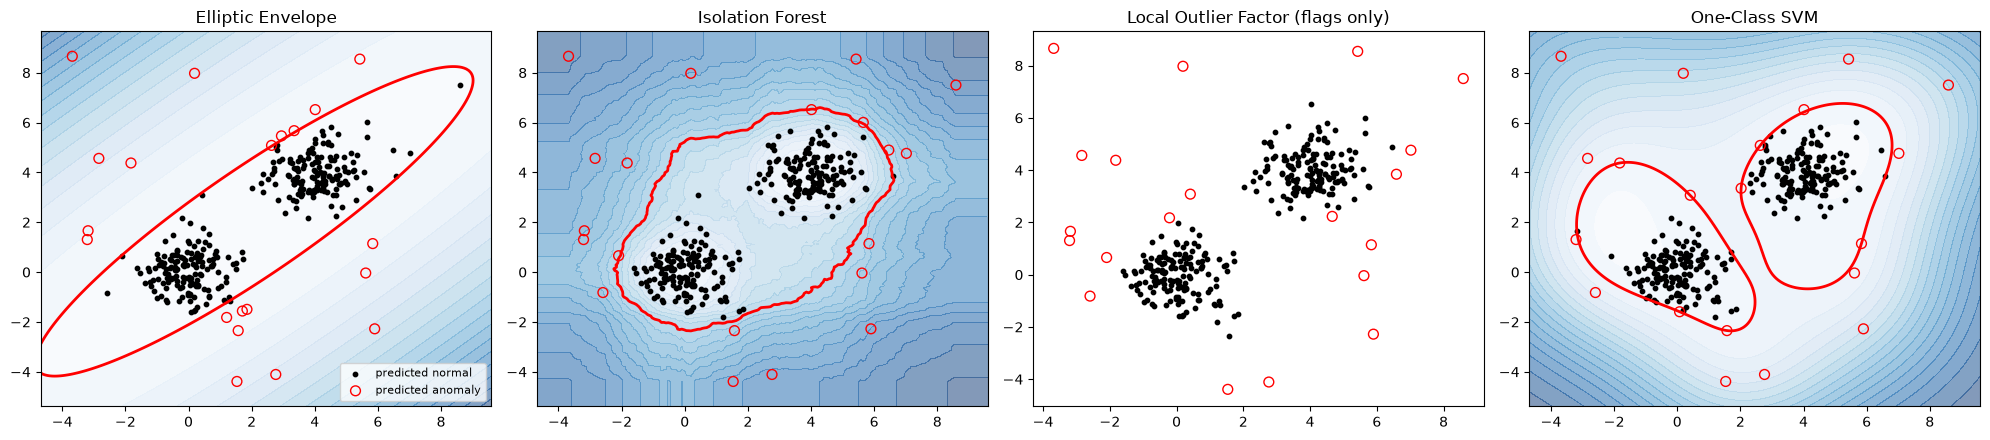

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, det) in zip(axes, detectors.items()):
    if name != 'Local Outlier Factor':
        plot_detector(ax, det, X, name)
    else:
        ax.set_title(name + ' (flags only)')
    pred = preds[name]
    ax.scatter(*X[pred == 1].T, s=10, c='black', label='predicted normal')
    ax.scatter(*X[pred == -1].T, s=50, facecolors='none', edgecolors='red',
               label='predicted anomaly')
axes[0].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

The red line marks each detector's boundary between "normal" and "anomalous". Elliptic Envelope draws one large ellipse around both groups, while Isolation Forest and One-Class SVM draw tighter regions around each group. LOF in outlier mode has no `decision_function` for new points, so only its flags are shown.

## 8. Novelty Detection: Training on Clean Data

In novelty detection, the model is trained only on normal data and later applied to new observations. LOF requires `novelty=True` for this, which enables `predict()` and `decision_function()` on unseen data.

In [6]:
X_train_clean = X_normal
X_new_normal, _ = make_blobs(n_samples=100, centers=[[0, 0], [4, 4]], cluster_std=0.8,
                             random_state=7)
X_new_anom = rng.uniform(low=-5, high=9, size=(15, 2))
X_new = np.vstack([X_new_normal, X_new_anom])
y_new = np.r_[np.ones(100), -np.ones(15)].astype(int)

novelty_models = {
    'LOF (novelty=True)': LocalOutlierFactor(n_neighbors=20, novelty=True),
    'Isolation Forest': IsolationForest(n_estimators=300, random_state=42),
    'One-Class SVM': make_pipeline(StandardScaler(), OneClassSVM(gamma=0.5, nu=0.05)),
}
for name, m in novelty_models.items():
    m.fit(X_train_clean)
    pred = m.predict(X_new)
    auc = roc_auc_score(y_new == -1, -m.decision_function(X_new))
    print(f'{name:>19}: anomalies caught = {((pred == -1) & (y_new == -1)).sum()}/15, '
          f'normal points wrongly flagged = {((pred == -1) & (y_new == 1)).sum()}/100, '
          f'ROC AUC = {auc:.3f}')

 LOF (novelty=True): anomalies caught = 13/15, normal points wrongly flagged = 9/100, ROC AUC = 0.943
   Isolation Forest: anomalies caught = 13/15, normal points wrongly flagged = 32/100, ROC AUC = 0.930
      One-Class SVM: anomalies caught = 12/15, normal points wrongly flagged = 7/100, ROC AUC = 0.937


Trained only on clean data, the detectors recognize most of the new anomalies while flagging only a few new normal points. Without a `contamination` value, Isolation Forest and LOF use a default threshold, so the trade-off between catching anomalies and false alarms can be adjusted by changing the threshold on the scores.

## 9. Effect of the Shape of the Data

The best detector depends on the shape of the normal data. On the curved **moons** data, methods that assume a single ellipse fail, while local or flexible methods follow the shape.

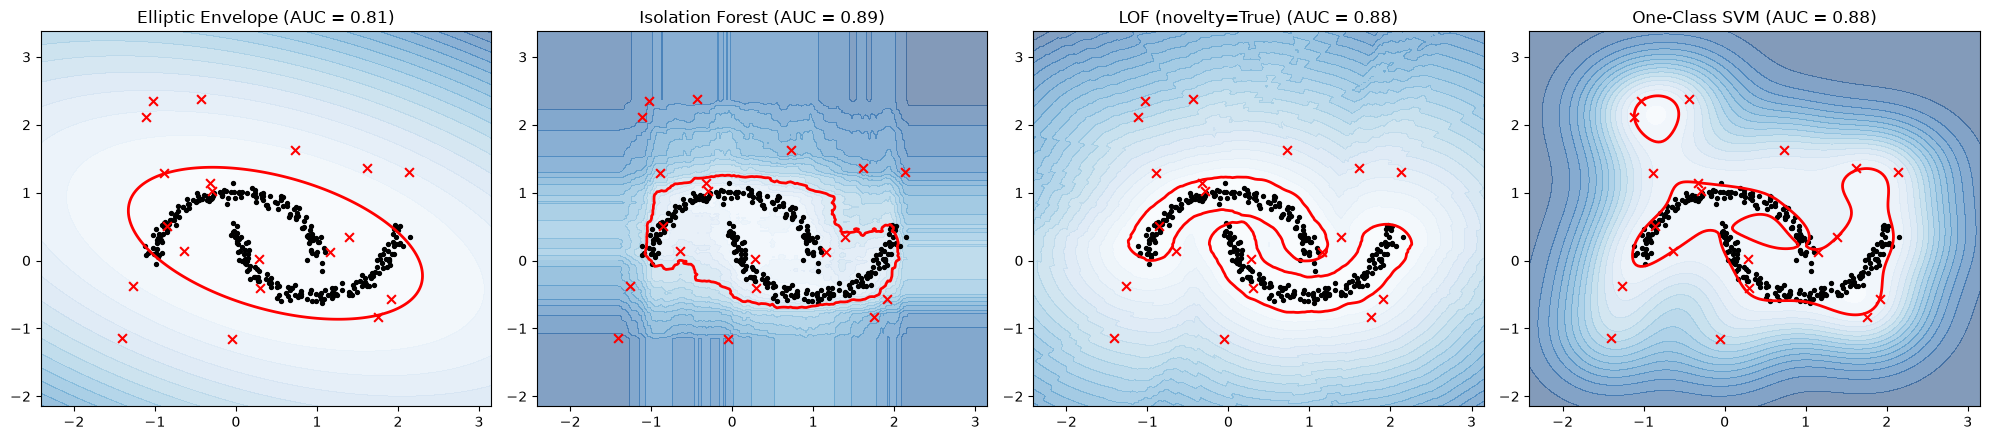

In [7]:
X_m, _ = make_moons(n_samples=300, noise=0.06, random_state=0)
X_m_anom = rng.uniform(low=-1.5, high=2.5, size=(20, 2))
X_moon = np.vstack([X_m, X_m_anom])
y_moon = np.r_[np.ones(300), -np.ones(20)].astype(int)
c = 20 / 320

moon_models = {
    'Elliptic Envelope': EllipticEnvelope(contamination=c, random_state=42),
    'Isolation Forest': IsolationForest(contamination=c, random_state=42),
    'LOF (novelty=True)': LocalOutlierFactor(n_neighbors=20, contamination=c, novelty=True),
    'One-Class SVM': OneClassSVM(gamma=2, nu=c),
}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, m) in zip(axes, moon_models.items()):
    m.fit(X_moon)
    auc = roc_auc_score(y_moon == -1, -m.decision_function(X_moon))
    plot_detector(ax, m, X_moon, f'{name} (AUC = {auc:.2f})')
    ax.scatter(*X_m.T, s=8, c='black')
    ax.scatter(*X_m_anom.T, s=40, c='red', marker='x')
plt.tight_layout()
plt.show()

On the moons data, Elliptic Envelope draws one ellipse that includes the empty space between the moons, so its ranking of anomalies is weaker. LOF and One-Class SVM follow the curved shape more closely, and Isolation Forest also adapts reasonably well. Visualizing the decision boundaries is a useful check when choosing a detector.

## Chapter Summary

- **Outlier detection** finds anomalies within contaminated training data; **novelty detection** trains on clean data and flags unusual new observations.
- All detectors share an API: `predict()` returns +1 (inlier) or -1 (outlier), and `decision_function()` / `score_samples()` give continuous scores where lower means more abnormal.
- **z-score** and **IQR** rules are simple but work per feature and miss anomalies that are only unusual in combination.
- **Elliptic Envelope** assumes elliptical, Gaussian-like data and uses the Mahalanobis distance.
- **Isolation Forest** isolates anomalies with random splits; it is fast, scalable, and shape-agnostic.
- **Local Outlier Factor** compares local densities and handles clusters of different densities; `novelty=True` enables scoring new data.
- **One-Class SVM** learns a flexible boundary around normal data but needs scaling and careful tuning of `gamma` and `nu`.
- `contamination` sets the decision threshold; when labels exist, detectors are evaluated with precision, recall, F1, and **ROC AUC** with anomalies as the positive class.